In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 17.6 — Graphical calculus for invariants

Source: SMSA 7.8, 2026-11-05, `smsa.pdf`. References below use section and equation numbers. Read the corresponding SMSA passage first. Native DisCoPy drawings run **top to bottom**: this preview reverses SMSA’s usual vertical flow while preserving left-to-right tensor order. A coupon replaces SMSA’s specialized glyph where necessary. This notebook uses no user-defined functions or assertion checks.



**Reading path.** Follow the complex map through its two bends, then close its indices and compare dual evaluation with a metric. Continue in `smsa_19_07.ipynb`: the dagger supplies conjugation, a partial trace closes one physical spin, and a matrix-product state contracts auxiliary wires while leaving physical spins open. The epsilon and projector examples below are further applications.

### Following a wire into a tensor index

SMSA 7.8, pp. 392–394, (17.87)–(17.95). Choose bases $e_i$ of $V=\mathbb C^2$ and $w_\alpha$ of $W=\mathbb C^3$. Our chosen map is
$$f(e_i)=\sum_{\alpha=1}^3 F_{\alpha i}w_\alpha,\qquad
F=\begin{pmatrix}1+i&2\\3&-i\\1-2i&4+i\end{pmatrix}.$$
The ordinary matrix has **output rows and input columns**. DisCoPy arrays put input axes first, so its array for $f:V\to W$ is `F.T`, with entries `array[i, alpha]`. This axis rearrangement changes storage order only. Python uses zero-based positions, so `F_idx[alpha-1, i-1]` corresponds to the source indices $\alpha,i$ starting at 1.

Let $w^\alpha(w_\beta)=\delta^\alpha_\beta$ and $e^i(e_j)=\delta^i_j$. In (17.87), bend the $W$ output into the **leftmost** input $W^*$:
$$\widetilde f:W^*\otimes V\to\mathbb C,\qquad
\widetilde f(w^\alpha\otimes e_i)=F_{\alpha i}.$$
In (17.88), bend the $V$ input into the **rightmost** output $V^*$:
$$\widehat f:\mathbb C\to W\otimes V^*,\qquad
\widehat f(1)=\sum_{\alpha,i}F_{\alpha i}w_\alpha\otimes e^i.$$
Thus $f^\alpha{}_i$, $f_{\bar\alpha,i}$ and $f^{\alpha,\bar i}$ have the same numbers in these bases, with different types. SMSA's barred index names a **dual basis**, not a complex conjugate. These bends use the bilinear dual pairing. They introduce neither a metric identifying $V$ with $V^*$ nor a Hermitian inner product.

The native compact types below retain that distinction as `V`, `V.r`, `W`, `W.r`. The finite tensor interpretation forgets the names but preserves their dimensions and order. The drawings read top to bottom and label the dual wires explicitly. SMSA (17.89) instead labels a reversed dual wire by the original space and draws its arrow the other way. Native bends have no arrow glyph here; a dagger would change the map and is not a replacement for an arrow.


In [1]:
import numpy as np
from discopy import compact, tensor
from discopy.drawing import Equation
V_idx, W_idx = compact.Ty('V'), compact.Ty('W')
f_idx = compact.Box('f', V_idx, W_idx)
F_idx = np.array([[1+1j, 2], [3, -1j], [1-2j, 4+1j]])
lowered_idx = (compact.Id(W_idx.r) @ f_idx) >> compact.Cup(W_idx.r, W_idx)
raised_idx = compact.Cap(V_idx, V_idx.r) >> (f_idx @ compact.Id(V_idx.r))
index_model = tensor.Functor({V_idx: 2, W_idx: 3}, {f_idx: F_idx.T},
                             dom=compact.Category(), dtype=complex)
print('Ordinary matrix F[alpha,i]:\n', F_idx)
print('f:', f_idx.dom, '->', f_idx.cod, '\ninput-first array[i,alpha]:\n', index_model(f_idx).array)
print('17.87:', lowered_idx.dom, '->', lowered_idx.cod)
print('Components [alpha,i]:\n', index_model(lowered_idx).array)
print('17.88:', raised_idx.dom, '->', raised_idx.cod)
print('Components [alpha,i]:\n', index_model(raised_idx).array)
print('Both bent arrays equal F:',
      np.array_equal(index_model(lowered_idx).array, F_idx),
      np.array_equal(index_model(raised_idx).array, F_idx))
print('They differ from conjugated F:',
      not np.array_equal(index_model(lowered_idx).array, F_idx.conjugate()))


Ordinary matrix F[alpha,i]:
 [[ 1.+1.j  2.+0.j]
 [ 3.+0.j -0.-1.j]
 [ 1.-2.j  4.+1.j]]
f: V -> W 
input-first array[i,alpha]:
 [[ 1.+1.j  3.+0.j  1.-2.j]
 [ 2.+0.j -0.-1.j  4.+1.j]]
17.87: W.r @ V -> Ty()
Components [alpha,i]:
 [[1.+1.j 2.+0.j]
 [3.+0.j 0.-1.j]
 [1.-2.j 4.+1.j]]
17.88: Ty() -> W @ V.r
Components [alpha,i]:
 [[1.+1.j 2.+0.j]
 [3.+0.j 0.-1.j]
 [1.-2.j 4.+1.j]]
Both bent arrays equal F: True True
They differ from conjugated F: True


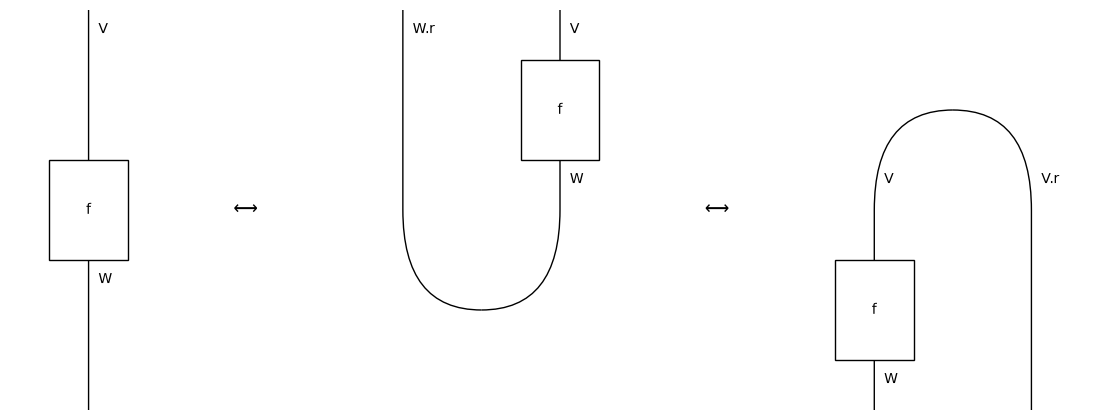

In [2]:
Equation(f_idx, lowered_idx, raised_idx, symbol=r'$\longleftrightarrow$').draw(
    figsize=(11, 4), draw_type_labels=True)


### A closed contraction, with every index visible

Choose $u=e_1+2i e_2$ and $\ell=2w^1-iw^2+(1+i)w^3$. The coefficients of the covector $\ell$ are specified directly. In particular, evaluating $\ell(w)$ is bilinear, with no implicit conjugation. Three ways of joining the same indices give
$$\ell(f(u))=\sum_{\alpha=1}^3\sum_{i=1}^2
\ell_\alpha F_{\alpha i}u^i
=\widetilde f(\ell\otimes u)
=(\ell\otimes\operatorname{ev}_u)\widehat f(1),$$
where $\operatorname{ev}_u(e^i)=u^i$. Each joined wire sums a matching vector/dual index, as in (17.95). The code prints the separate contributions before the sum.


In [3]:
u_idx = compact.Box('u', compact.Ty(), V_idx)
ell_idx = compact.Box('ell', W_idx, compact.Ty())
ell_state_idx = compact.Box('ell in W*', compact.Ty(), W_idx.r)
u_eval_idx = compact.Box('ev_u', V_idx.r, compact.Ty())
u_values_idx = np.array([1, 2j])
ell_values_idx = np.array([2, -1j, 1+1j])
contraction_model = tensor.Functor(
    {V_idx: 2, W_idx: 3},
    {f_idx: F_idx.T, u_idx: u_values_idx, ell_idx: ell_values_idx,
     ell_state_idx: ell_values_idx, u_eval_idx: u_values_idx},
    dom=compact.Category(), dtype=complex)
straight_scalar_idx = u_idx >> f_idx >> ell_idx
lowered_scalar_idx = (ell_state_idx @ u_idx) >> lowered_idx
raised_scalar_idx = raised_idx >> (ell_idx @ u_eval_idx)
scalar_values_idx = np.array([contraction_model(straight_scalar_idx).array.item(),
    contraction_model(lowered_scalar_idx).array.item(),
    contraction_model(raised_scalar_idx).array.item()])
contributions_idx = ell_values_idx[:, None] * F_idx * u_values_idx[None, :]
expected_scalar_idx = (ell_values_idx @ F_idx @ u_values_idx).item()
print('Contributions ell_alpha F_alpha_i u_i, rows alpha, columns i:\n', contributions_idx)
print('Three native closed diagrams:', scalar_values_idx)
print('Expected sum:', expected_scalar_idx)
print('All agree:', np.array_equal(scalar_values_idx, np.repeat(expected_scalar_idx, 3)))
print('Conjugating ell would instead give:', ell_values_idx.conjugate() @ F_idx @ u_values_idx)
print('Dual map type:', f_idx.transpose().dom, '->', f_idx.transpose().cod)
print('Dual map f*: W* -> V*, ordinary matrix F.T:\n',
      index_model(f_idx.transpose()).array.T)
print('Hermitian adjoint f-dagger: W -> V, ordinary matrix conjugate(F).T:\n',
      index_model(f_idx.dagger()).array.T)
print('Dual differs from adjoint:',
      not np.array_equal(index_model(f_idx.transpose()).array, index_model(f_idx.dagger()).array))

open_output_idx = contraction_model(u_idx >> f_idx).array
print('Open W wire, components indexed by alpha:', open_output_idx)
print('Expected [1+5j,5,-1+6j]:', np.array([1+5j,5,-1+6j]))
print('Open output agrees:', np.array_equal(open_output_idx, np.array([1+5j,5,-1+6j])))


Contributions ell_alpha F_alpha_i u_i, rows alpha, columns i:
 [[  2.+2.j   0.+8.j]
 [  0.-3.j  -0.-2.j]
 [  3.-1.j -10.+6.j]]
Three native closed diagrams: [-5.+10.j -5.+10.j -5.+10.j]
Expected sum: (-5+10j)
All agree: True
Conjugating ell would instead give: (7+22j)
Dual map type: W.r -> V.r
Dual map f*: W* -> V*, ordinary matrix F.T:
 [[1.+1.j 3.+0.j 1.-2.j]
 [2.+0.j 0.-1.j 4.+1.j]]
Hermitian adjoint f-dagger: W -> V, ordinary matrix conjugate(F).T:
 [[ 1.-1.j  3.-0.j  1.+2.j]
 [ 2.-0.j -0.+1.j  4.-1.j]]
Dual differs from adjoint: True
Open W wire, components indexed by alpha: [ 1.+5.j  5.+0.j -1.+6.j]
Expected [1+5j,5,-1+6j]: [ 1.+5.j  5.+0.j -1.+6.j]
Open output agrees: True


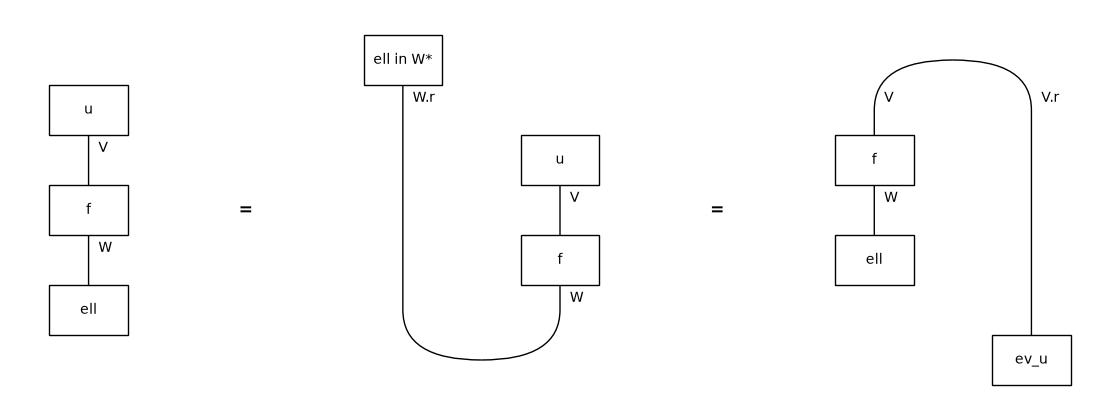

In [4]:
Equation(straight_scalar_idx, lowered_scalar_idx, raised_scalar_idx).draw(
    figsize=(11, 4), draw_type_labels=True)


### Dual pairing and a metric are different data

In (17.91)–(17.94), SMSA also draws tensors with two indices of the same variance. Their source pictures use two arrows pointing the same way and a black metric mark. That is additional data, beyond the mixed vector/dual evaluation. For example, choose the symmetric bilinear form $G=\operatorname{diag}(2,3)$ on $V$. This is our example, not a Killing-form calculation. It sends $u^i$ to $u_i=\sum_jG_{ij}u^j$. The inverse form has entries $G^{ij}$ and recovers $u^i$. Replacing these forms by the identity would change the tensors. Neither operation conjugates components.


In [5]:
G_idx = np.diag([2, 3])
G_inverse_idx = np.diag([1/2, 1/3])
metric_idx = compact.Box('G', V_idx @ V_idx, compact.Ty())
inverse_metric_idx = compact.Box('G inverse', compact.Ty(), V_idx @ V_idx)
metric_model = tensor.Functor({V_idx: 2},
    {metric_idx: G_idx, inverse_metric_idx: G_inverse_idx},
    dom=compact.Category(), dtype=complex)
metric_snake_idx = (compact.Id(V_idx) @ inverse_metric_idx) >> (metric_idx @ compact.Id(V_idx))
print('G_ij:\n', metric_model(metric_idx).array)
print('G^ij:\n', metric_model(inverse_metric_idx).array)
print('Lowered components G u:', G_idx @ u_values_idx)
print('Recovered components G inverse G u:', G_inverse_idx @ G_idx @ u_values_idx)
print('Metric contraction gives identity:\n', metric_model(metric_snake_idx).array)
print('Equal to identity:', np.array_equal(metric_model(metric_snake_idx).array, np.eye(2)))

wrong_metric_model = tensor.Functor({V_idx: 2},
    {metric_idx: G_idx, inverse_metric_idx: G_idx},
    dom=compact.Category(), dtype=complex)
print('Control: G used in place of its inverse:\n', wrong_metric_model(metric_snake_idx).array)
print('Identity (expected False):', np.array_equal(wrong_metric_model(metric_snake_idx).array, np.eye(2)))


G_ij:
 [[2.+0.j 0.+0.j]
 [0.+0.j 3.+0.j]]
G^ij:
 [[0.5       +0.j 0.        +0.j]
 [0.        +0.j 0.33333333+0.j]]
Lowered components G u: [2.+0.j 0.+6.j]
Recovered components G inverse G u: [1.+0.j 0.+2.j]
Metric contraction gives identity:
 [[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
Equal to identity: True
Control: G used in place of its inverse:
 [[4.+0.j 0.+0.j]
 [0.+0.j 9.+0.j]]
Identity (expected False): False


### The antisymmetric tensors

Equation (17.82), with the two-dimensional antisymmetric tensor: represent the tensor as a native `tensor.Box` with two output wires, then compose with a native swap. In this selected basis the components are $\epsilon^{12}=1$, $\epsilon^{21}=-1$. The illustration tests antisymmetry; it does not encode a Lie algebra action.


In [6]:
from discopy import tensor
V = tensor.Dim(2)
epsilon = tensor.Box('epsilon', tensor.Dim(), V @ V, [0, 1, -1, 0])
flipped = epsilon >> tensor.Swap(V, V)
actual = flipped.eval().array
expected = -epsilon.eval().array
print('17.82 swapped entries:')
print(actual)
print('Expected negative entries:')
print(expected)
print('Equal:', (actual == expected).all())

17.82 swapped entries:
[[ 0 -1]
 [ 1  0]]
Expected negative entries:
[[ 0 -1]
 [ 1  0]]
Equal: True


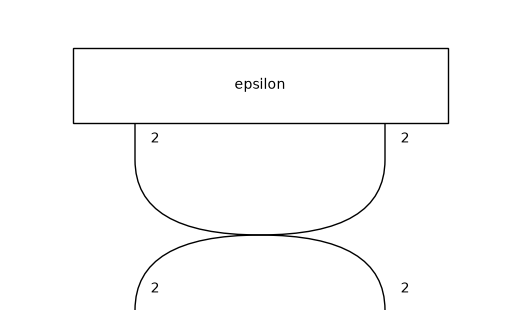

In [7]:
flipped.draw(figsize=(5, 3))

Equations (17.96)–(17.97): take the three-dimensional Levi-Civita array in ordered basis $1,2,3$. Input axes precede output axes. The real array makes dagger a transpose, so composing the two tensors contracts their third indices. This gives an evaluated translation with four boundary wires. The stored array of `eps3` is indexed `[i,j,k]` (two inputs, one output). The contraction array is `[i,j,l,m]`; reshaping uses row pair `(i,j)` and column pair `(l,m)`, each in lexicographic order `11,12,...,33`.

17.97 contracted entries:
[[ 0  0  0  0  0  0  0  0  0]
 [ 0  1  0 -1  0  0  0  0  0]
 [ 0  0  1  0  0  0 -1  0  0]
 [ 0 -1  0  1  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  0 -1  0]
 [ 0  0 -1  0  0  0  1  0  0]
 [ 0  0  0  0  0 -1  0  1  0]
 [ 0  0  0  0  0  0  0  0  0]]
Expected identity minus swap:
[[ 0  0  0  0  0  0  0  0  0]
 [ 0  1  0 -1  0  0  0  0  0]
 [ 0  0  1  0  0  0 -1  0  0]
 [ 0 -1  0  1  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  0 -1  0]
 [ 0  0 -1  0  0  0  1  0  0]
 [ 0  0  0  0  0 -1  0  1  0]
 [ 0  0  0  0  0  0  0  0  0]]
Equal: True


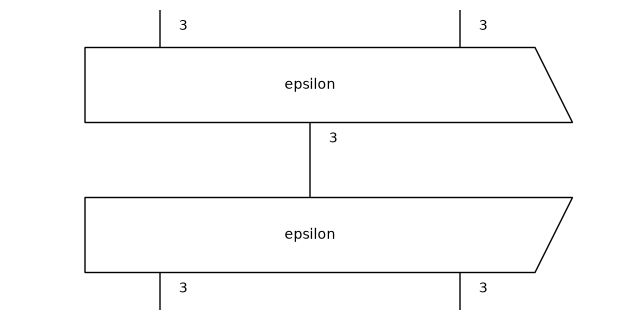

In [8]:
V3 = tensor.Dim(3)
eps3 = tensor.Box('epsilon', V3 @ V3, V3, [0, 0, 0, 0, 0, 1, 0, -1, 0, 0, 0, -1, 0, 0, 0, 1, 0, 0, 0, 1, 0, -1, 0, 0, 0, 0, 0])
contraction = eps3 >> eps3.dagger()
actual = contraction.eval().array
expected = tensor.Id(V3 @ V3).eval().array - tensor.Swap(V3, V3).eval().array
print('17.97 contracted entries:')
print(actual.reshape(9, 9))
print('Expected identity minus swap:')
print(expected.reshape(9, 9))
print('Equal:', (actual == expected).all())
contraction.draw(figsize=(6, 3))

### The trace projector in one two-dimensional example

SMSA pp. 395–396, (17.99)–(17.100), gives $\xi_0=1/\dim V$. Here take $\dim V=2$ and identify $V\otimes V^*$ with matrices by $e_i\otimes e^j\leftrightarrow E_{ij}$. Closing the two input wires takes $\operatorname{tr}A$; opening the output pair gives $I$. Thus
$$p_0(A)=\frac12\operatorname{tr}(A)I,\qquad
(p_0)_{ij}{}^{kl}=\frac12\delta_{ij}\delta_{kl}.$$
For our chosen $A=\begin{pmatrix}1+i&2\\-i&3-i\end{pmatrix}$ the output is $2I$. The extra closed loop in $p_0^2$ evaluates to $2$, which explains the factor $1/2$ in this example. The native four-index array below checks all components of this finite projector. It supplies no general decomposition of $V\otimes V^*$.
 The printed input-first projector array has axes `[i,j,k,l]`: input vector/dual pair `(i,j)`, then output vector/dual pair `(k,l)`. Its 4 by 4 display uses ordered pairs `11,12,21,22` on each axis.

17.99 type: V @ V.r -> V @ V.r
p0 input-first components [i,j,k,l] as 4 by 4:
 [[0.5+0.j 0. +0.j 0. +0.j 0.5+0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0.5+0.j 0. +0.j 0. +0.j 0.5+0.j]]
Expected delta_ij delta_kl / 2:
 [[0.5 0.  0.  0.5]
 [0.  0.  0.  0. ]
 [0.  0.  0.  0. ]
 [0.5 0.  0.  0.5]]
All components agree: True
p0(A):
 [[2.+0.j 0.+0.j]
 [0.+0.j 2.+0.j]]
Expected trace(A) I / 2:
 [[2.+0.j 0.+0.j]
 [0.+0.j 2.+0.j]]
Action agrees: True
p0 squared equals p0: True
Closed loop: (2+0j)
Control: omit 1/2, square:
 [[2.+0.j 0.+0.j 0.+0.j 2.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [2.+0.j 0.+0.j 0.+0.j 2.+0.j]]
Unnormalized map itself:
 [[1.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [1.+0.j 0.+0.j 0.+0.j 1.+0.j]]
Idempotent (expected False): False


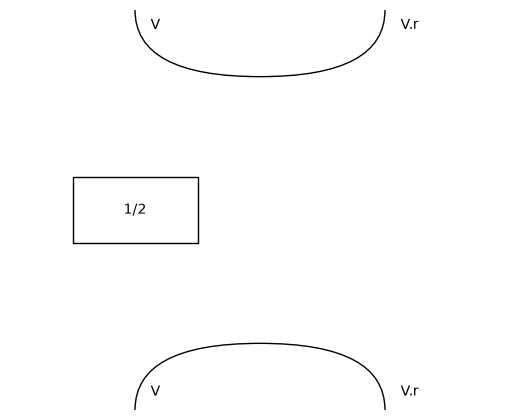

In [9]:
trace_idx = compact.Cup(V_idx, V_idx.r)
identity_state_idx = compact.Cap(V_idx, V_idx.r)
half_idx = compact.Box('1/2', compact.Ty(), compact.Ty())
p0_idx = trace_idx >> (half_idx @ identity_state_idx)
A_values_idx = np.array([[1+1j, 2], [-1j, 3-1j]])
A_idx = compact.Box('A', compact.Ty(), V_idx @ V_idx.r)
projector_model = tensor.Functor({V_idx: 2},
    {half_idx: 0.5, A_idx: A_values_idx}, dom=compact.Category(), dtype=complex)
p0_array_idx = projector_model(p0_idx).array
p0_expected_idx = np.einsum('ij,kl->ijkl', np.eye(2), np.eye(2)) / 2
projected_A_idx = projector_model(A_idx >> p0_idx).array
print('17.99 type:', p0_idx.dom, '->', p0_idx.cod)
print('p0 input-first components [i,j,k,l] as 4 by 4:\n', p0_array_idx.reshape(4, 4))
print('Expected delta_ij delta_kl / 2:\n', p0_expected_idx.reshape(4, 4))
print('All components agree:', np.array_equal(p0_array_idx, p0_expected_idx))
print('p0(A):\n', projected_A_idx)
print('Expected trace(A) I / 2:\n', np.trace(A_values_idx) * np.eye(2) / 2)
print('Action agrees:', np.array_equal(projected_A_idx, np.trace(A_values_idx) * np.eye(2) / 2))
print('p0 squared equals p0:', np.array_equal(projector_model(p0_idx >> p0_idx).array, p0_array_idx))
print('Closed loop:', projector_model(identity_state_idx >> trace_idx).array)
p0_idx.draw(figsize=(5, 4), draw_type_labels=True)

unnormalized_idx = trace_idx >> identity_state_idx
print('Control: omit 1/2, square:\n', projector_model(unnormalized_idx >> unnormalized_idx).array.reshape(4,4))
print('Unnormalized map itself:\n', projector_model(unnormalized_idx).array.reshape(4,4))
print('Idempotent (expected False):', np.array_equal(projector_model(unnormalized_idx >> unnormalized_idx).array, projector_model(unnormalized_idx).array))


### A chosen adjoint projector: traceless two by two matrices

SMSA 7.8, p. 396, (17.101)–(17.105) describes the adjoint image, but (17.101) has unresolved indices and (17.103)–(17.105) contain `PIC`/`XXX`. The following is a **chosen finite reconstruction of the stated image, not a literal transcription or an accepted repair**. The trace-pairing correction proposed in the errata has not been accepted.

Choose the defining representation of $\mathfrak{sl}_2$ with
$$T_1=H=\begin{pmatrix}1&0\\0&-1\end{pmatrix},\quad
T_2=E=\begin{pmatrix}0&1\\0&0\end{pmatrix},\quad
T_3=F=\begin{pmatrix}0&0\\1&0\end{pmatrix}.$$
Let $B_{ab}=\operatorname{tr}(T_aT_b)$. Then
$$B=\begin{pmatrix}2&0&0\\0&0&1\\0&1&0\end{pmatrix},\qquad
p_{\rm ad}(A)=\sum_{a,b}T_a(B^{-1})_{ab}\operatorname{tr}(T_bA)
=A-\tfrac12\operatorname{tr}(A)I.$$
The generator coupon $t:\mathfrak g\otimes V\to V$ has components $(T_a)_{ij}$. A cap turns it into $e:\mathfrak g\to V\otimes V^*$, $e(T_a)=T_a$. Its native dual $e^*:V\otimes V^*\to\mathfrak g^*$ gives the trace pairing, not a Hermitian adjoint. The explicitly supplied box $B^{-1}:\mathfrak g^*\to\mathfrak g$ closes the generator index. For this chosen representation the Killing form is $\kappa=4B$ (independently checked from commutators in C-033). Using $\kappa^{-1}$ therefore needs an overall factor $4$ to recover this projector. We do not assign a canonical value to the source's ambiguous $\xi_{\rm ad}$.


In [10]:
G_ad_idx = compact.Ty('g')
generator_values_idx = np.array([[[1,0],[0,-1]], [[0,1],[0,0]], [[0,0],[1,0]]])
B_trace_idx = np.einsum('aij,bji->ab', generator_values_idx, generator_values_idx)
B_inverse_idx = np.linalg.inv(B_trace_idx)
t_ad_idx = compact.Box('t', G_ad_idx @ V_idx, V_idx)
embed_ad_idx = (compact.Id(G_ad_idx) @ compact.Cap(V_idx, V_idx.r)) >> (t_ad_idx @ compact.Id(V_idx.r))
trace_ad_idx = embed_ad_idx.transpose(left=True)
inverse_B_idx = compact.Box(r'$B^{-1}$', G_ad_idx.r, G_ad_idx)
pad_idx = trace_ad_idx >> inverse_B_idx >> embed_ad_idx
generator_model = tensor.Functor({G_ad_idx:3, V_idx:2},
    {t_ad_idx:generator_values_idx.transpose(0,2,1), inverse_B_idx:B_inverse_idx,
     half_idx:0.5, A_idx:A_values_idx}, dom=compact.Category(), dtype=complex)
pad_array_idx = generator_model(pad_idx).array
pad_expected_idx = np.eye(4).reshape(2,2,2,2) - p0_expected_idx
pad_A_idx = generator_model(A_idx >> pad_idx).array
print('B = trace(T_a T_b):\n', B_trace_idx, '\nB inverse:\n', B_inverse_idx)
print('Generator t:', t_ad_idx.dom, '->', t_ad_idx.cod)
print('Embedding:', embed_ad_idx.dom, '->', embed_ad_idx.cod)
print('Trace dual:', trace_ad_idx.dom, '->', trace_ad_idx.cod)
print('Adjoint projector input-first array [i,j,k,l]:\n', pad_array_idx.reshape(4,4))
print('Equals identity minus p0 on all coefficients:', np.array_equal(pad_array_idx, pad_expected_idx))
print('p_ad(A):\n', pad_A_idx, '\nExpected A-trace(A)I/2:\n', A_values_idx-np.trace(A_values_idx)*np.eye(2)/2)
print('Action agrees:', np.array_equal(pad_A_idx, A_values_idx-np.trace(A_values_idx)*np.eye(2)/2))
print('Rank (expected 3):', np.linalg.matrix_rank(pad_array_idx.reshape(4,4)))
print('Idempotent:', np.array_equal(generator_model(pad_idx >> pad_idx).array, pad_array_idx))
wrong_B_model = tensor.Functor({G_ad_idx:3, V_idx:2},
    {t_ad_idx:generator_values_idx.transpose(0,2,1), inverse_B_idx:np.eye(3)},
    dom=compact.Category(), dtype=complex)
print('Control: identity instead of inverse B agrees (expected False):',
      np.array_equal(wrong_B_model(pad_idx).array, pad_expected_idx))
print('Control idempotent (expected False):', np.array_equal(wrong_B_model(pad_idx >> pad_idx).array, wrong_B_model(pad_idx).array))


B = trace(T_a T_b):
 [[2 0 0]
 [0 0 1]
 [0 1 0]] 
B inverse:
 [[0.5 0.  0. ]
 [0.  0.  1. ]
 [0.  1.  0. ]]
Generator t: g @ V -> V
Embedding: g -> V @ V.r
Trace dual: V @ V.r -> g.r
Adjoint projector input-first array [i,j,k,l]:
 [[ 0.5+0.j  0. +0.j  0. +0.j -0.5+0.j]
 [ 0. +0.j  1. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  1. +0.j  0. +0.j]
 [-0.5+0.j  0. +0.j  0. +0.j  0.5+0.j]]
Equals identity minus p0 on all coefficients: True
p_ad(A):
 [[-1.+1.j  2.+0.j]
 [ 0.-1.j  1.-1.j]] 
Expected A-trace(A)I/2:
 [[-1.+1.j  2.+0.j]
 [-0.-1.j  1.-1.j]]
Action agrees: True
Rank (expected 3): 3
Idempotent: True
Control: identity instead of inverse B agrees (expected False): False
Control idempotent (expected False): False


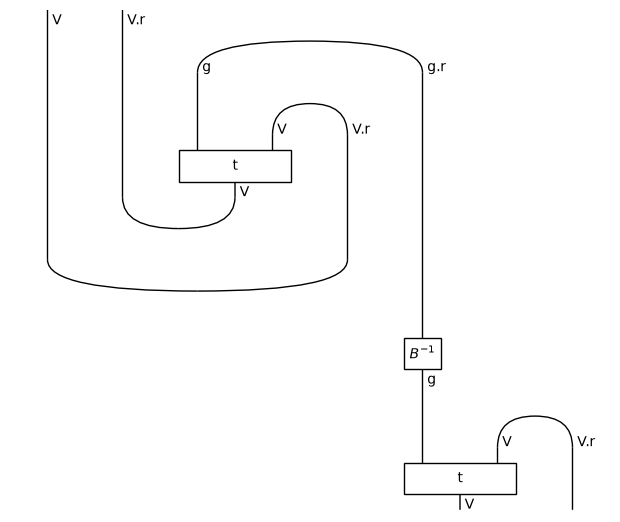

In [11]:
pad_idx.draw(figsize=(6,5), draw_type_labels=True)


### A chosen orthogonal example: three complementary images

For $V=\mathbb R^3$, choose the Euclidean bilinear form explicitly: $\operatorname{ev}(e_i\otimes e_j)=\delta_{ij}$ and $\operatorname{coev}(1)=\sum_i e_i\otimes e_i$. These are supplied metric boxes on $V\otimes V$, not an implicit identification of a dual wire with a vector wire. Under $e_i\otimes e_j\leftrightarrow E_{ij}$, the swap acts as $A\mapsto A^T$. Native sums of diagrams give
$$P_0=\tfrac13\operatorname{coev}\circ\operatorname{ev},\quad
P_{\rm ad}=\tfrac12(\mathrm{id}-\mathrm{swap}),\quad
P_{\rm sy}=\tfrac12(\mathrm{id}+\mathrm{swap})-P_0.$$
Thus $P_{\rm sy}(A)=(A+A^T)/2-\operatorname{tr}(A)I/3$. The three images are scalar, antisymmetric and symmetric tracefree matrices. Their ranks are $1,3,5$ and their sum is the identity. Our nonsymmetric integer matrix is chosen for this notebook.

This is a **chosen finite reconstruction of the stated image, not a literal transcription or an accepted repair** of (17.106)–(17.109). The missing glyph in (17.106) prevents a precise interpretation of the source's $\eta_{\rm sy}$ and its sign. Its normalization remains a question for the author. The drawings below use semicolons to separate different maps. Their sum, rather than their equality, is the identity.


In [12]:
V_so_idx = compact.Ty('R3')
ev_so_idx = compact.Box('Euclidean ev', V_so_idx @ V_so_idx, compact.Ty())
coev_so_idx = compact.Box('Euclidean coev', compact.Ty(), V_so_idx @ V_so_idx)
third_so_idx = compact.Box('1/3', compact.Ty(), compact.Ty())
half_so_idx = compact.Box('1/2', compact.Ty(), compact.Ty())
minus_half_so_idx = compact.Box('-1/2', compact.Ty(), compact.Ty())
minus_third_so_idx = compact.Box('-1/3', compact.Ty(), compact.Ty())
id_so_idx, swap_so_idx = compact.Id(V_so_idx @ V_so_idx), compact.Swap(V_so_idx, V_so_idx)
p0_so_idx = ev_so_idx >> (third_so_idx @ coev_so_idx)
pad_so_idx = (half_so_idx @ id_so_idx) + (minus_half_so_idx @ swap_so_idx)
psy_so_idx = (half_so_idx @ id_so_idx) + (half_so_idx @ swap_so_idx) + (ev_so_idx >> (minus_third_so_idx @ coev_so_idx))
A_so_idx = np.array([[2,1,-3],[4,-1,2],[0,5,6]])
A_so_box_idx = compact.Box('A3', compact.Ty(), V_so_idx @ V_so_idx)
so_projector_model = tensor.Functor({V_so_idx:3},
    {ev_so_idx:np.eye(3), coev_so_idx:np.eye(3), third_so_idx:1/3,
     half_so_idx:0.5, minus_half_so_idx:-0.5, minus_third_so_idx:-1/3,
     A_so_box_idx:A_so_idx}, dom=compact.Category(), dtype=complex)
p0_so_array_idx = so_projector_model(p0_so_idx).array
pad_so_array_idx = so_projector_model(pad_so_idx).array
psy_so_array_idx = so_projector_model(psy_so_idx).array
so_arrays_idx = [p0_so_array_idx, pad_so_array_idx, psy_so_array_idx]
so_expected_idx = [np.trace(A_so_idx)*np.eye(3)/3,
    (A_so_idx-A_so_idx.T)/2, (A_so_idx+A_so_idx.T)/2-np.trace(A_so_idx)*np.eye(3)/3]
print('Chosen A:\n', A_so_idx)
for label_so_idx, diagram_so_idx, array_so_idx, expected_so_idx in zip(
        ['scalar','antisymmetric','symmetric tracefree'], [p0_so_idx,pad_so_idx,psy_so_idx], so_arrays_idx, so_expected_idx):
    print(label_so_idx, 'action:\n', so_projector_model(A_so_box_idx >> diagram_so_idx).array)
    print('Expected:\n', expected_so_idx)
    print('Action agrees:', np.allclose(so_projector_model(A_so_box_idx >> diagram_so_idx).array, expected_so_idx, atol=1e-14, rtol=0))
    print('Rank:', np.linalg.matrix_rank(array_so_idx.reshape(9,9)),
          'idempotent:', np.allclose(so_projector_model(diagram_so_idx >> diagram_so_idx).array, array_so_idx, atol=1e-14, rtol=0))
print('Pairwise products zero:', all(np.allclose(left_so_idx.reshape(9,9) @ right_so_idx.reshape(9,9), 0, atol=1e-14, rtol=0)
    for i_so_idx,left_so_idx in enumerate(so_arrays_idx) for j_so_idx,right_so_idx in enumerate(so_arrays_idx) if i_so_idx != j_so_idx))
print('Sum is identity on all 81 coefficients:', np.allclose(sum(so_arrays_idx), np.eye(9).reshape(3,3,3,3), atol=1e-14, rtol=0))


Chosen A:
 [[ 2  1 -3]
 [ 4 -1  2]
 [ 0  5  6]]
scalar action:
 [[2.33333333+0.j 0.        +0.j 0.        +0.j]
 [0.        +0.j 2.33333333+0.j 0.        +0.j]
 [0.        +0.j 0.        +0.j 2.33333333+0.j]]
Expected:
 [[2.33333333 0.         0.        ]
 [0.         2.33333333 0.        ]
 [0.         0.         2.33333333]]
Action agrees: True
Rank: 1 idempotent: True
antisymmetric action:
 [[ 0. +0.j -1.5+0.j -1.5+0.j]
 [ 1.5+0.j  0. +0.j -1.5+0.j]
 [ 1.5+0.j  1.5+0.j  0. +0.j]]
Expected:
 [[ 0.  -1.5 -1.5]
 [ 1.5  0.  -1.5]
 [ 1.5  1.5  0. ]]
Action agrees: True
Rank: 3 idempotent: True
symmetric tracefree action:
 [[-0.33333333+0.j  2.5       +0.j -1.5       +0.j]
 [ 2.5       +0.j -3.33333333+0.j  3.5       +0.j]
 [-1.5       +0.j  3.5       +0.j  3.66666667+0.j]]
Expected:
 [[-0.33333333  2.5        -1.5       ]
 [ 2.5        -3.33333333  3.5       ]
 [-1.5         3.5         3.66666667]]
Action agrees: True
Rank: 5 idempotent: True
Pairwise products zero: True
Sum is identity

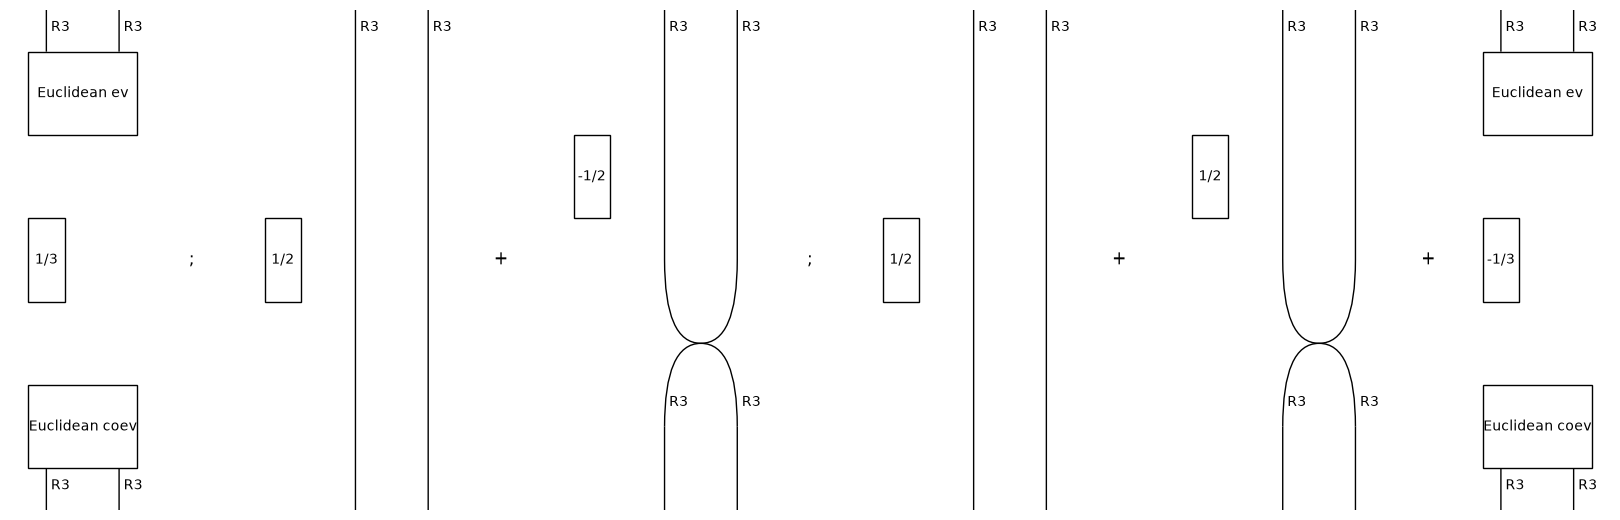

In [13]:
Equation(p0_so_idx, pad_so_idx, psy_so_idx, symbol=';').draw(
    figsize=(16,5), draw_type_labels=True)


Remaining source questions: (17.98) permits omitting a flip as a drawing convention, but the source explicitly does not adopt that convention in its following pictures; the missing specialized glyphs and the index/normalization questions in (17.101)–(17.109) still need the author. The two concrete reconstructions above test only the displayed finite models (C-033). Exercise 17.6.19 remains for the reader. The native preview reads top to bottom with explicit types; SMSA's flexible oriented-wire convention is explained in (17.89)–(17.94).
